<a href="https://colab.research.google.com/github/sm-shreya09/Machine_Learning_Notebooks/blob/main/outlier_detection(Z_score).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('placement.csv')

In [ ]:
df.shape

(200, 2)

In [ ]:
df.sample(7)

,cgpa,package
91,6.22,2.14
41,6.89,2.70
177,7.09,3.64
68,7.56,2.99
195,6.93,2.46
171,8.01,3.76
42,5.95,2.54


/tmp/ipykernel_2120/304206339.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['cgpa'], kde=True)
/tmp/ipykernel_2120/304206339.py:6: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['package'], kde=True)


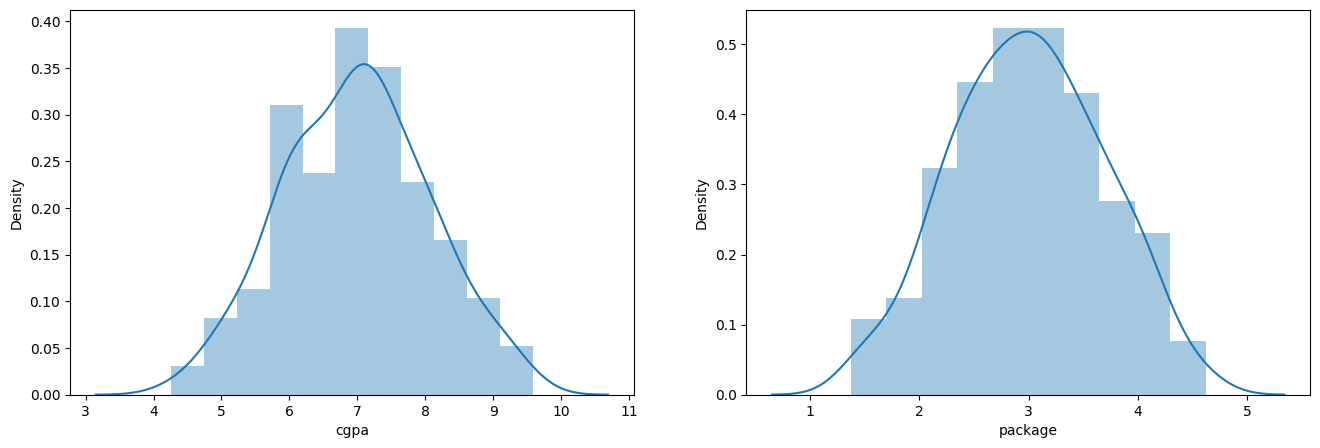

In [ ]:
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
sns.distplot(df['cgpa'], kde=True)

plt.subplot(1,2,2)
sns.distplot(df['package'], kde=True)

plt.show()

In [ ]:
print("Mean value of cgpa", df['cgpa'].mean())
print("std value of cgpa", df['cgpa'].std())
print("Min value of cgpa", df['cgpa'].min())
print("Max value of cgpa", df['cgpa'].max())

Mean value of cgpa 6.990500000000001
std value of cgpa 1.0694086798895523
Min value of cgpa 4.26
Max value of cgpa 9.58


In [ ]:
 #finding boundary values

 print("highest allowed", df['cgpa'].mean()+3*df['cgpa'].std())
 print("lowest allowed", df['cgpa'].mean()-3*df['cgpa'].std())

highest allowed 10.198726039668658
lowest allowed 3.7822739603313438


In [ ]:
#finding the outliers
df[(df['cgpa'] > 10.198) | (df['cgpa'] < 3.78)]

,cgpa,package


# **TRIMIMING**

In [ ]:
new_df = df[(df['cgpa']< 10.198) & (df['cgpa']> 3.78)]
new_df

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57
...,...,...
195,6.93,2.46
196,5.89,2.57
197,7.21,3.24
198,7.63,3.96


# **Z-score**

In [ ]:
df['cgpa_zscore'] = (df['cgpa'] - df['cgpa'].mean())/df['cgpa'].std()
df.head()

,cgpa,package,cgpa_zscore
0,6.89,3.26,-0.093977
1,5.12,1.98,-1.749097
2,7.82,3.25,0.775662
3,7.42,3.67,0.401624
4,6.94,3.57,-0.047222


In [ ]:
df[df['cgpa_zscore']>2]

,cgpa,package,cgpa_zscore
40,9.38,4.02,2.234412
50,9.58,4.43,2.421432
51,9.26,3.79,2.122201
63,9.16,4.25,2.028691
169,9.31,4.37,2.168956


In [ ]:
df[df['cgpa_zscore']<-2]

,cgpa,package,cgpa_zscore
84,4.26,1.53,-2.553280
85,4.79,1.48,-2.057679
88,4.73,1.48,-2.113785
143,4.85,1.54,-2.001573
193,4.57,1.94,-2.263400


In [ ]:
df[(df['cgpa_zscore'] > 2) | (df['cgpa_zscore'] < -2)]

,cgpa,package,cgpa_zscore
40,9.38,4.02,2.234412
50,9.58,4.43,2.421432
51,9.26,3.79,2.122201
63,9.16,4.25,2.028691
84,4.26,1.53,-2.553280
85,4.79,1.48,-2.057679
88,4.73,1.48,-2.113785
143,4.85,1.54,-2.001573
169,9.31,4.37,2.168956
193,4.57,1.94,-2.263400


# **Capping**

In [ ]:
#calculatinng new upper and lower limit
upper_limit = df['cgpa'].mean() + 3*df['cgpa'].std()
lower_limit = df['cgpa'].mean() - 3*df['cgpa'].std()

In [ ]:
df['cgpa'] = np.where(
    df['cgpa']>upper_limit,
    upper_limit,
    np.where(
        df['cgpa']<lower_limit,
        lower_limit,
        df['cgpa']
    )
)

In [ ]:
df.shape

(200, 3)

In [ ]:
df['cgpa'].describe()

,cgpa
count,200.000000
mean,6.990500
std,1.069409
min,4.260000
25%,6.190000
50%,6.965000
75%,7.737500
max,9.580000
